# v6_holiday — 공휴일 구조화로 잔차 개선

주모델 **v3c**의 잔차가 **공휴일(특히 음력 연휴)에서 깨진다**는 진단에서 출발한 v6 변형군(v6a~g).
단일 `is_holiday`를 공휴일 유형·연휴 길이·명절로 구조화해, **잔차를 백색잡음까지 정리**하고
**예측구간을 v3c보다 샤프**하게 만들었다. 대표 변형 = **v6g(포화 명절, log run)**.

- 스크립트: `src/model_arimax_v6_holiday.py` · 산출: `data/processed/arimax/v6_results.csv`, `v6{c,d,e,f,g}_forecast.csv`
- 계보/결론: `src/MODELS.md`, `docs/research_log/2026-05-31_1500_v6_공휴일_구조화_잔차개선.md`
- **점예측 성능은 v3c가 여전히 최고** — v6는 잔차·구간 개선 변형(주모델 미교체).

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
import seaborn as sns

warnings.filterwarnings("ignore")
# 한글 폰트 (eda/modeling.ipynb와 동일)
NOTO_PATH = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if NOTO_PATH.exists():
    font_manager.fontManager.addfont(str(NOTO_PATH))
KOR_FONT = "Noto Sans CJK JP"
mpl.rcParams["font.family"] = KOR_FONT
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", rc={"font.family": KOR_FONT})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
ARI = ROOT / "data" / "processed" / "arimax"

res = pd.read_csv(ARI / "v6_results.csv", encoding="utf-8-sig")
res["short"] = res["model"].str.split().str[0]   # v3c, v6a, ...

# 공휴일 마스크 (원천)
hol = pd.read_csv(ROOT / "data" / "raw" / "holidays_2010_2025.csv",
                  encoding="utf-8-sig", parse_dates=["date"])
HOL = set(hol.loc[hol["is_holiday"] == "Y", "date"])
LUNAR = set(hol.loc[hol["name"].isin(["설날", "추석"]), "date"])

def load_fc(tag):
    f = pd.read_csv(ARI / f"{tag}_forecast.csv", encoding="utf-8-sig",
                    parse_dates=["tm"]).set_index("tm")
    return f

print("ARI:", ARI)
res[["short", "n_exog", "AIC", "MAE_2025", "Winkler", "resid_skew", "resid_kurt", "LB_p_lag10"]].round(3)

ARI: /home/jmlee/research/timeseries-final/data/processed/arimax


,short,n_exog,AIC,MAE_2025,Winkler,resid_skew,resid_kurt,LB_p_lag10
0,v3c,14,-23830.960,2667.510,18304.861,-1.755,13.900,0.000
1,v6a,15,-24575.424,2859.195,16377.674,-1.051,9.325,0.068
2,v6b,17,-24991.628,2746.446,21924.220,-0.793,9.563,0.000
3,v6c,18,-25030.406,2705.510,26620.564,-0.765,10.093,0.000
4,v6d,15,-24179.509,3070.769,17995.499,-1.146,9.475,0.000
5,v6e,16,-24589.994,2859.940,16375.237,-1.022,9.263,0.056
6,v6f,15,-24575.451,2868.455,16474.980,-1.049,9.310,0.062
7,v6g,16,-24576.341,2826.970,16153.564,-1.018,9.328,0.105


## 1. 잔차 정규성 — 공휴일이 v3c 꼬리를 만든다

v3c 잔차는 skew −1.75·kurtosis 13.9·Ljung-Box p 5e-5(백색잡음 기각). 공휴일 구조화 변형은
꼬리(kurtosis)를 낮추고 자기상관을 해소한다. **포화 명절 v6g가 LB p=0.105로 가장 깨끗**.

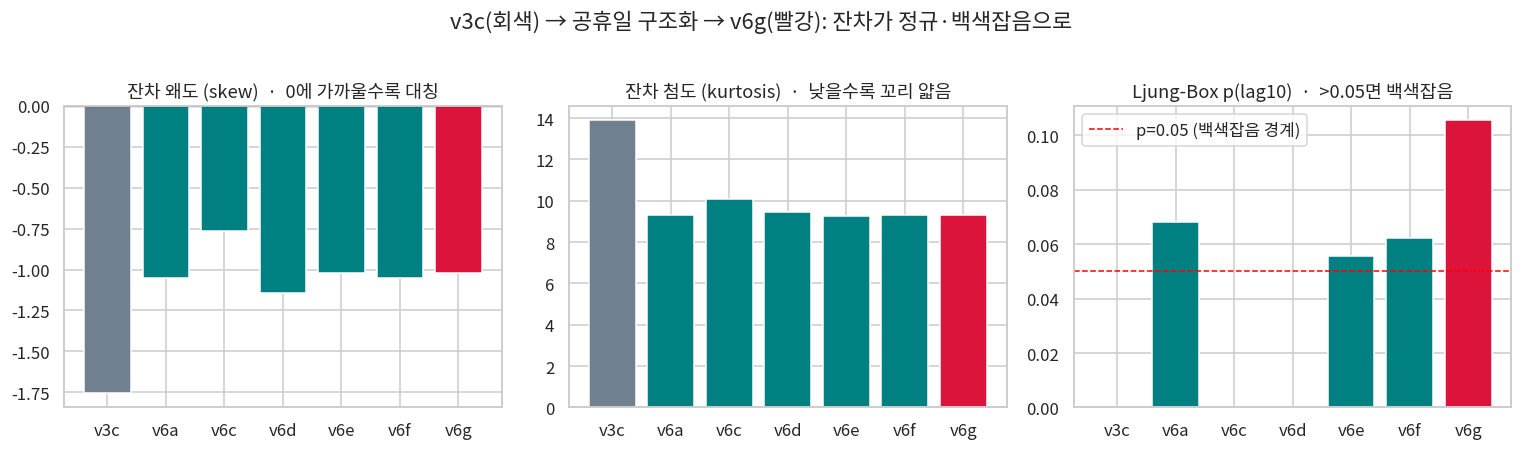

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
order = ["v3c", "v6a", "v6c", "v6d", "v6e", "v6f", "v6g"]
d = res.set_index("short").reindex(order)
colors = ["slategray"] + ["teal"] * 5 + ["crimson"]   # v3c 회색, v6g 강조

ax[0].bar(order, d["resid_skew"], color=colors)
ax[0].set_title("잔차 왜도 (skew)  ·  0에 가까울수록 대칭")
ax[0].axhline(0, color="k", lw=0.8)

ax[1].bar(order, d["resid_kurt"], color=colors)
ax[1].set_title("잔차 첨도 (kurtosis)  ·  낮을수록 꼬리 얇음")
ax[1].axhline(0, color="k", lw=0.8)

ax[2].bar(order, d["LB_p_lag10"], color=colors)
ax[2].axhline(0.05, color="red", ls="--", lw=1, label="p=0.05 (백색잡음 경계)")
ax[2].set_title("Ljung-Box p(lag10)  ·  >0.05면 백색잡음")
ax[2].legend()
for a in ax:
    a.tick_params(axis="x", rotation=0)
fig.suptitle("v3c(회색) → 공휴일 구조화 → v6g(빨강): 잔차가 정규·백색잡음으로", y=1.02)
plt.tight_layout(); plt.show()

## 2. 트레이드오프 — 점예측(MAE) vs 구간(Winkler)

x=one-shot MAE(작을수록 점예측 좋음), y=Winkler(작을수록 구간 좋음). **v3c는 점예측 최고
(왼쪽)**, **v6g는 구간 최저(아래)**. v6c는 명절을 강하게 잡아 점예측은 낫지만 장기 구간이
폭발(위로 튐).

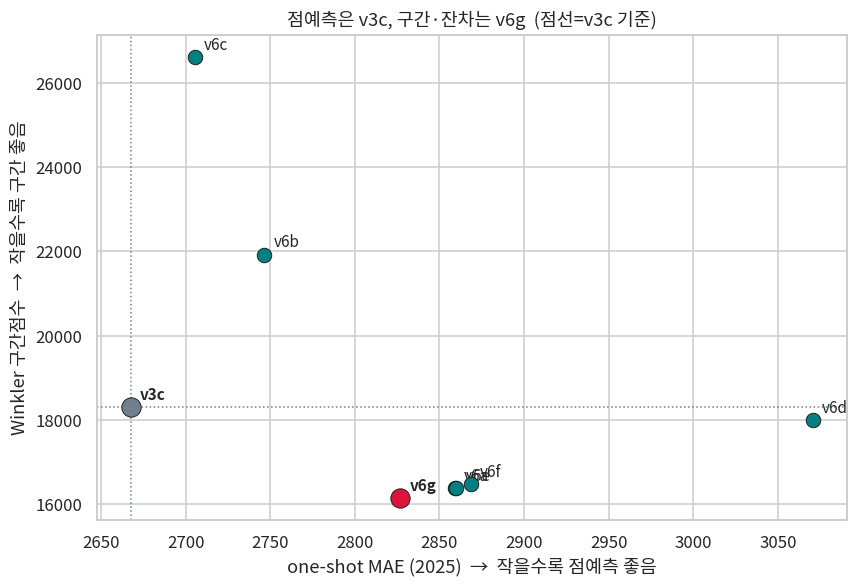

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in res.iterrows():
    s = r["short"]
    is_main = s == "v3c"; is_rep = s == "v6g"
    c = "slategray" if is_main else ("crimson" if is_rep else "teal")
    ax.scatter(r["MAE_2025"], r["Winkler"], s=160 if (is_main or is_rep) else 90,
               color=c, zorder=3, edgecolor="k", linewidth=0.6)
    ax.annotate(s, (r["MAE_2025"], r["Winkler"]),
                xytext=(6, 5), textcoords="offset points", fontsize=10,
                fontweight="bold" if (is_main or is_rep) else "normal")
ax.axhline(res.set_index("short").loc["v3c", "Winkler"], color="slategray", ls=":", lw=1)
ax.axvline(res.set_index("short").loc["v3c", "MAE_2025"], color="slategray", ls=":", lw=1)
ax.set_xlabel("one-shot MAE (2025)  →  작을수록 점예측 좋음")
ax.set_ylabel("Winkler 구간점수  →  작을수록 구간 좋음")
ax.set_title("점예측은 v3c, 구간·잔차는 v6g  (점선=v3c 기준)")
plt.tight_layout(); plt.show()

## 3. 명절 정확도 — one-shot MAE 분해 (음력 / 공휴일 / 평일)

v3c는 **음력 연휴에서 10,387 MW** 오차(단일 더미 한계). v6는 음력을 크게 잡는다(v6c −71%,
v6g −54%). 대신 **평일이 조금 흔들린다**(명절을 잡으며 ARMA 재추정) — 이게 점예측 비용.

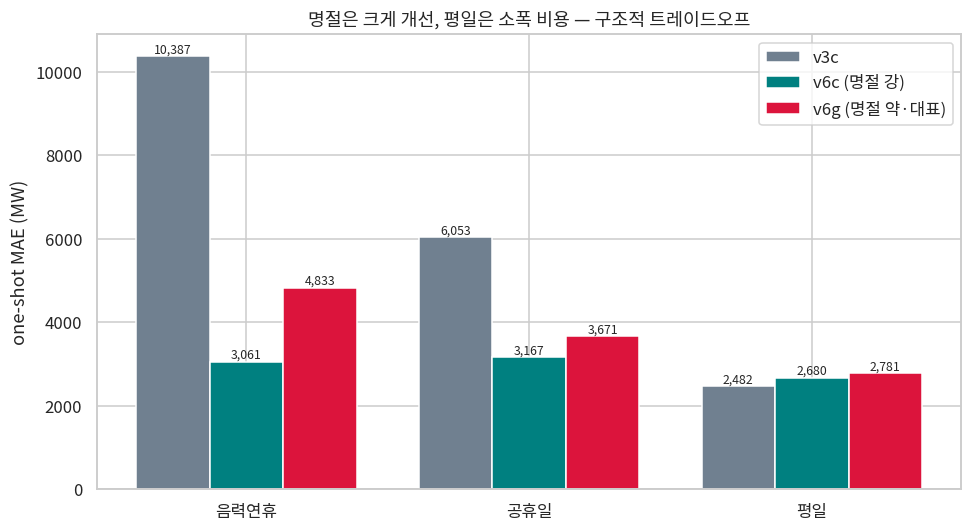

In [4]:
def decomp(tag):
    f = load_fc(tag)
    e = (f["actual"] - f["pred"]).abs()
    return {
        "음력연휴": e[f.index.isin(LUNAR)].mean(),
        "공휴일": e[f.index.isin(HOL)].mean(),
        "평일": e[~f.index.isin(HOL)].mean(),
    }

tags = {"v3c": "v3c", "v6c (명절 강)": "v6c", "v6g (명절 약·대표)": "v6g"}
dd = pd.DataFrame({k: decomp(v) for k, v in tags.items()}).T
groups = ["음력연휴", "공휴일", "평일"]
x = np.arange(len(groups)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 5))
for i, (k, c) in enumerate(zip(dd.index, ["slategray", "teal", "crimson"])):
    ax.bar(x + (i - 1) * w, dd.loc[k, groups], w, label=k, color=c)
    for j, g in enumerate(groups):
        ax.annotate(f"{dd.loc[k, g]:,.0f}", (x[j] + (i - 1) * w, dd.loc[k, g]),
                    ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(groups)
ax.set_ylabel("one-shot MAE (MW)")
ax.set_title("명절은 크게 개선, 평일은 소폭 비용 — 구조적 트레이드오프")
ax.legend()
plt.tight_layout(); plt.show()

## 4. v6g 예측 — 2025 명절 구간 (설날·추석)

2025 설날(1월말)·추석(10월초)에서 v3c는 과대예측(수요 붕괴 못 따라감), **v6g는 명절 붕괴를
추종**. 평일 구간은 두 모델이 거의 겹친다.

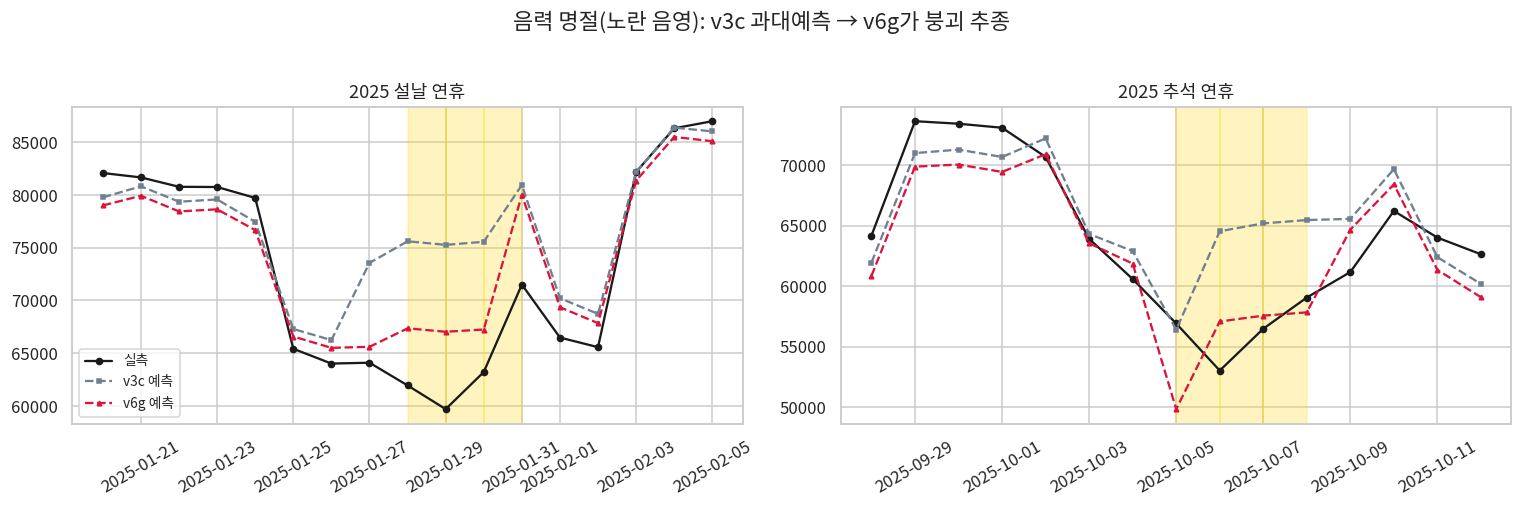

In [5]:
f3 = load_fc("v3c"); f6 = load_fc("v6g")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for k, (lo, hi, ttl) in enumerate({
        "설날": ("2025-01-20", "2025-02-05", "2025 설날 연휴"),
        "추석": ("2025-09-28", "2025-10-12", "2025 추석 연휴")}.values()):
    a = ax[k]
    s3 = f3.loc[lo:hi]; s6 = f6.loc[lo:hi]
    a.plot(s3.index, s3["actual"], "o-", color="k", lw=1.5, ms=4, label="실측")
    a.plot(s3.index, s3["pred"], "s--", color="slategray", ms=3, label="v3c 예측")
    a.plot(s6.index, s6["pred"], "^--", color="crimson", ms=3, label="v6g 예측")
    for d in s3.index:
        if d in LUNAR:
            a.axvspan(d, d + pd.Timedelta(days=1), color="gold", alpha=0.25)
    a.set_title(ttl); a.tick_params(axis="x", rotation=30)
    if k == 0:
        a.legend(loc="lower left", fontsize=9)
fig.suptitle("음력 명절(노란 음영): v3c 과대예측 → v6g가 붕괴 추종", y=1.02)
plt.tight_layout(); plt.show()

### 요약

- **잔차 개선 성공**: v6g가 Ljung-Box p 5e-5→**0.105(백색잡음 통과)**, Winkler 18,305→**16,154
  (v3c보다 샤프)**, 음력 예측오차 10,387→4,833 MW.
- **점예측은 v3c 유지**: one-shot MAE 2,668(v3c) < 2,827(v6g). 명절을 잡으면 ARMA 재추정으로
  평일이 흔들리는 **구조적 비용** → 주모델은 v3c.
- **명절은 약하게(포화 log run)** 넣는 v6g가 잔차·구간·점예측 균형의 최적. 상세: `src/MODELS.md`.